<a href="https://colab.research.google.com/github/LuisManuelCatzoliSoriano/Simulaci-n_II/blob/main/EM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ciertas tasas de interés siguen un modelo de Cox-Ingersoll-Ross, $dx_t=c(x_t-\mu)dt+\sigma\sqrt{x_t}dw_t$, con $c=-0.35$, $\mu=6$, $\sigma=0.03$ y $x_0=6.01$.

Usando Euler-Murayama, se quiere estimar $E(x_5)$; para ello se usa Euler-Murayama para estimar $n$ veces $x_5$ y se promedian valores.

Trate de encontrar una relación entre la varianza de esta estimación y $\Delta t$

E(x5) exacto = 6.001738   Var(x5) exacta = 7.485026e-03

     dt  media est.       sesgo   Var(x5) sim  Var(x5) teor  Var estimador
  1.000    6.001159   -5.79e-04    9.2795e-03    9.2288e-03     9.2795e-08
  0.500    6.001851    1.14e-04    8.2444e-03    8.2775e-03     8.2444e-08
  0.250    6.001514   -2.24e-04    7.8933e-03    7.8640e-03     7.8933e-08
  0.100    6.001794    5.65e-05    7.6133e-03    7.6327e-03     7.6133e-08
  0.050    6.001548   -1.90e-04    7.5975e-03    7.5583e-03     7.5975e-08
  0.020    6.002139    4.01e-04    7.5494e-03    7.5142e-03     7.5494e-08
  0.010    6.002227    4.90e-04    7.5334e-03    7.4996e-03     7.5334e-08
  0.005    6.001837    9.97e-05    7.4472e-03    7.4923e-03     7.4472e-08

Ajuste simulado : Var(x5) ≈ 7.4707e-03 + 1.7533e-03·Δt
Ajuste teórico  : Var(x5) ≈ 7.4651e-03 + 1.7296e-03·Δt
Var exacta (Δt→0) = 7.4850e-03
=> Var(estimador) ≈ (7.471e-03 + 1.753e-03·Δt)/n


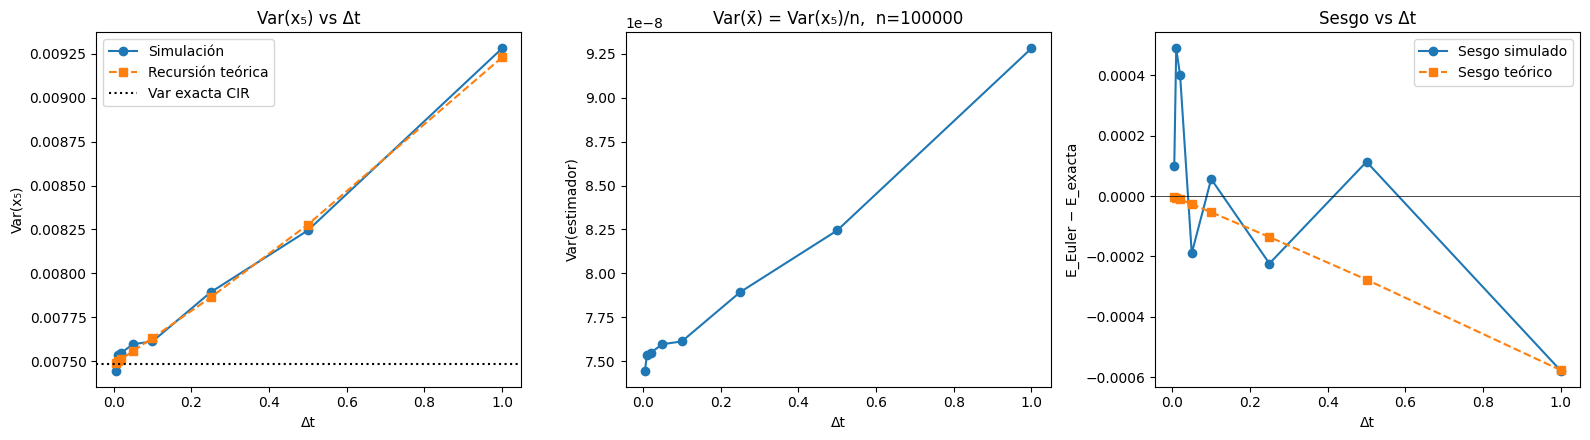

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- Parámetros ----------------
c, mu, sigma, x0, T = -0.35, 6.0, 0.03, 6.01, 5.0
kappa = -c
n = 100_000                      # trayectorias por cada Δt
dts = np.array([1, 0.5, 0.25, 0.1, 0.05, 0.02, 0.01, 0.005])
rng = np.random.default_rng(123)

# ---------------- Euler-Maruyama ----------------
def euler_cir(dt, n, rng):
    N = int(round(T/dt))
    x = np.full(n, x0)
    for _ in range(N):
        z = rng.standard_normal(n)
        x = x + c*(x - mu)*dt + sigma*np.sqrt(np.maximum(x, 0)*dt)*z  # truncación completa
    return x

# ---------------- Valores exactos del CIR ----------------
E_exact = mu + (x0 - mu)*np.exp(-kappa*T)
V_exact = (x0*sigma**2/kappa)*(np.exp(-kappa*T) - np.exp(-2*kappa*T)) \
        + (mu*sigma**2/(2*kappa))*(1 - np.exp(-kappa*T))**2

# ---------------- Recursión teórica del esquema de Euler ----------------
def euler_moments(dt):
    N = int(round(T/dt)); a = 1 + c*dt
    m, v = x0, 0.0
    for _ in range(N):
        v = a**2*v + sigma**2*dt*m
        m = a*m - c*mu*dt
    return m, v

# ---------------- Simulación ----------------
res = []
for dt in dts:
    x5 = euler_cir(dt, n, rng)
    mean_hat = x5.mean()
    var_x5 = x5.var(ddof=1)
    var_est = var_x5/n                      # Var del estimador
    m_th, v_th = euler_moments(dt)
    res.append((dt, mean_hat, var_x5, var_est, m_th, v_th))
res = np.array(res)

print(f"E(x5) exacto = {E_exact:.6f}   Var(x5) exacta = {V_exact:.6e}\n")
print(f"{'dt':>7} {'media est.':>11} {'sesgo':>11} {'Var(x5) sim':>13} {'Var(x5) teor':>13} {'Var estimador':>14}")
for dt, mh, vx, ve, mt, vt in res:
    print(f"{dt:7.3f} {mh:11.6f} {mh-E_exact:11.2e} {vx:13.4e} {vt:13.4e} {ve:14.4e}")

# ---------------- Ajuste lineal Var_dt(x5) ≈ V0 + V1*dt ----------------
V1, V0 = np.polyfit(res[:,0], res[:,2], 1)
V1t, V0t = np.polyfit(res[:,0], res[:,5], 1)
print(f"\nAjuste simulado : Var(x5) ≈ {V0:.4e} + {V1:.4e}·Δt")
print(f"Ajuste teórico  : Var(x5) ≈ {V0t:.4e} + {V1t:.4e}·Δt")
print(f"Var exacta (Δt→0) = {V_exact:.4e}")
print(f"=> Var(estimador) ≈ ({V0:.3e} + {V1:.3e}·Δt)/n")

# ---------------- Gráficas ----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(res[:,0], res[:,2], 'o-', label='Simulación')
ax[0].plot(res[:,0], res[:,5], 's--', label='Recursión teórica')
ax[0].axhline(V_exact, color='k', ls=':', label='Var exacta CIR')
ax[0].set_xlabel('Δt'); ax[0].set_ylabel('Var(x₅)'); ax[0].legend(); ax[0].set_title('Var(x₅) vs Δt')

ax[1].plot(res[:,0], res[:,3], 'o-')
ax[1].set_xlabel('Δt'); ax[1].set_ylabel('Var(estimador)'); ax[1].set_title(f'Var(x̄) = Var(x₅)/n,  n={n}')

ax[2].plot(res[:,0], res[:,1]-E_exact, 'o-', label='Sesgo simulado')
ax[2].plot(res[:,0], res[:,4]-E_exact, 's--', label='Sesgo teórico')
ax[2].axhline(0, color='k', lw=.5)
ax[2].set_xlabel('Δt'); ax[2].set_ylabel('E_Euler − E_exacta'); ax[2].legend(); ax[2].set_title('Sesgo vs Δt')

plt.tight_layout(); plt.show()